# Validación estadística y análisis de incertidumbre

### Walk-forward, bootstrap y cuantificación de la dispersión

**Grupo 5** — Maestría en Inteligencia Artificial Aplicada, UDLA

---

Los cuadernos anteriores reportan **un número sobre un único periodo**: MAPE del 4,1 % en
enero–septiembre de 2026. Eso no dice si el resultado es estable o si el periodo elegido fue
favorable.

Este cuaderno responde tres preguntas que un solo periodo no puede responder:

1. **¿El modelo gana de forma consistente, o ganó una vez?** — validación walk-forward
2. **¿Cuánta incertidumbre tiene esa cifra?** — intervalos por bootstrap
3. **¿Cuánto puede desviarse una predicción concreta?** — intervalos de predicción

### Por qué no se usa validación cruzada k-fold

Es la técnica habitual, y aquí sería **incorrecta**. Repartir los meses al azar entre pliegues
pondría a junio en el entrenamiento para predecir mayo: el modelo vería el futuro. En series
temporales eso es fuga de información por construcción, y produce métricas optimistas que no se
reproducen en producción.

El equivalente correcto es la **validación de origen rodante** (*walk-forward*): entrenar con
todo lo anterior a un mes, predecir ese mes, avanzar y repetir. Se obtienen muchas evaluaciones
independientes sin romper el orden temporal.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
sys.modules["bottleneck"] = None

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.config import REPORTES, SEMILLA

pd.set_option("display.width", 200)
plt.rcParams.update({"figure.figsize": (11, 3.8), "axes.grid": True, "grid.alpha": .3,
                     "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
PROC = RAIZ / "data" / "processed"
AZUL, NARANJA, VERDE, GRIS, ROJO = "#2a78d6", "#eb6834", "#1baf7a", "#888780", "#e34948"

w = pd.read_parquet(PROC / "v7_walkforward.parquet")
w["mes_s"] = pd.to_datetime(w.mes).dt.strftime("%Y-%m")
print(f"Orígenes de evaluación: {w.mes.nunique()} "
      f"({w.mes_s.min()} a {w.mes_s.max()}) · {w.modelo.nunique()} modelos")

Orígenes de evaluación: 21 (2025-01 a 2026-09) · 4 modelos


## 1. Diseño de la validación walk-forward

Para cada mes $M$ desde enero de 2025 hasta septiembre de 2026:

1. Se entrena **solo con los meses anteriores a $M$**
2. Se predice $M$
3. Se avanza un mes y se repite, con el entrenamiento creciendo

Son **21 evaluaciones independientes**, cada una sobre datos que el modelo no vio. Se incluye el
baseline ingenuo —repetir el mes anterior— porque es la referencia mínima: un modelo que no lo
supere no aporta nada.

In [2]:
t = w[w.modelo == "Tasa de conversión"].sort_values("mes")
pd.DataFrame([
    ("Orígenes evaluados", w.mes.nunique()),
    ("Primer entrenamiento", f"{t.n_train.min()} filas"),
    ("Último entrenamiento", f"{t.n_train.max()} filas"),
    ("Meses evaluados", f"{t.mes_s.min()} a {t.mes_s.max()}"),
], columns=["", "valor"]).set_index("")

,valor
,
Orígenes evaluados,21
Primer entrenamiento,88 filas
Último entrenamiento,308 filas
Meses evaluados,2025-01 a 2026-09


## 2. ¿Gana de forma consistente?

In [3]:
r = (w.groupby("modelo")
       .agg(MAPE_medio=("ape", "mean"), mediana=("ape", "median"), desv=("ape", "std"),
            p10=("ape", lambda s: s.quantile(.10)), p90=("ape", lambda s: s.quantile(.90)),
            peor=("ape", "max"), MAE=("ae", "mean"))
       .round(2).sort_values("MAPE_medio"))
r

,MAPE_medio,mediana,desv,p10,p90,peor,MAE
modelo,,,,,,,
Tasa de conversión,5.26,4.24,4.35,1.12,10.89,17.52,76.70
Random Forest,7.17,5.77,5.06,1.79,11.26,23.41,103.23
XGBoost Poisson,10.56,9.44,7.30,1.91,18.97,28.11,142.63
Naive (mes anterior),34.96,28.43,39.67,9.03,46.85,196.12,360.67


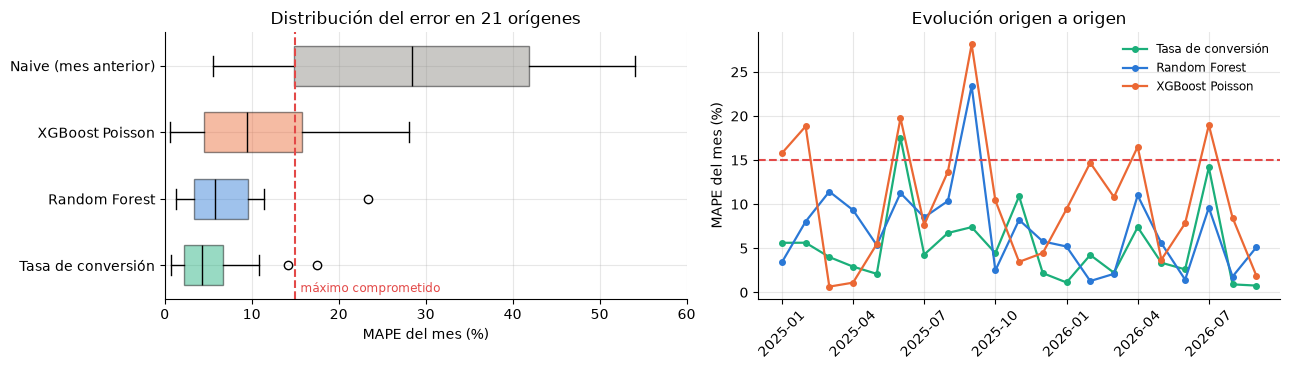

In [4]:
orden = r.index.tolist()
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
datos = [w[w.modelo == m].ape.values for m in orden]
bp = ax[0].boxplot(datos, vert=False, patch_artist=True, widths=.6)
ax[0].set_yticks(range(1, len(orden)+1), orden)
for caja, c in zip(bp["boxes"], [VERDE, AZUL, NARANJA, GRIS]):
    caja.set_facecolor(c); caja.set_alpha(.45)
for m in bp["medians"]: m.set_color("black")
ax[0].axvline(15, ls="--", color=ROJO)
ax[0].text(15.6, .6, "máximo comprometido", color=ROJO, fontsize=8.5)
ax[0].set_xlabel("MAPE del mes (%)"); ax[0].set_xlim(0, 60)
ax[0].set_title("Distribución del error en 21 orígenes")

for m, c in zip(orden[:3], [VERDE, AZUL, NARANJA]):
    s = w[w.modelo == m].sort_values("mes")
    ax[1].plot(range(len(s)), s.ape.values, marker="o", ms=4, lw=1.6, color=c, label=m)
ax[1].axhline(15, ls="--", color=ROJO)
ax[1].set_xticks(range(0, len(t), 3), t.mes_s.values[::3], rotation=45)
ax[1].set_ylabel("MAPE del mes (%)"); ax[1].legend(frameon=False, fontsize=8.5)
ax[1].set_title("Evolución origen a origen")
plt.tight_layout(); plt.savefig(REPORTES / "figuras" / "f7_walkforward.png", dpi=130); plt.show()

El orden se mantiene en las 21 evaluaciones, y no por poco: el modelo de tasa promedia **5,26 %**
frente a 7,17 % de Random Forest y 10,56 % de XGBoost. El baseline ingenuo queda en 34,96 %, lo
que confirma que el problema no es trivial.

Dos lecturas que conviene no pasar por alto.

**El peor origen del modelo supera el umbral.** En junio de 2025 falló un 17,5 %, por encima del
15 % comprometido. Es 1 de 21, pero existe: el criterio se cumple de media y en el periodo de
prueba, no en todos los meses posibles.

**La dispersión también importa.** Con desviación de 4,35 puntos, el modelo de tasa no solo es
más certero sino más estable que Random Forest (5,06) y XGBoost (7,30).

In [5]:
peores = t.nlargest(4, "ape")[["mes_s", "real", "pred", "ae", "ape"]].round(1)
print(f"Orígenes por encima del 15 %: {(t.ape > 15).sum()} de {len(t)}\n")
peores

Orígenes por encima del 15 %: 1 de 21



,mes_s,real,pred,ae,ape
20,2025-06,2244.0,1850.8,393.2,17.5
72,2026-07,1364.0,1170.8,193.2,14.2
40,2025-11,1274.0,1412.8,138.8,10.9
32,2025-09,2098.0,1942.9,155.1,7.4


### ¿Y frente a no tener un modelo?

Superar a otros modelos no responde a la pregunta del negocio, que es si el modelo anticipa algo que un método trivial no anticiparía. Se añaden dos referencias sencillas, evaluadas con el mismo walk-forward y los mismos 21 orígenes:

- **Cero:** no anticipa ninguna devolución. Es lo que equivale a no tener método.
- **Media móvil de 3 meses:** para cada marca, el promedio de sus tres meses anteriores.

Se calculan aparte (`src/validacion.py`) y no alteran la tabla `v7_walkforward` de arriba.

In [6]:
from src import validacion as V

panel = pd.read_parquet(PROC / "v6_panel_modelo.parquet")
lineas_base = V.lineas_base(panel)
comparativa = V.resumen(pd.concat([w, lineas_base], ignore_index=True))
comparativa.to_csv(REPORTES / "walkforward_con_lineas_base.csv")
mejor = comparativa.loc["Tasa de conversión", "MAPE_medio"]
for nombre in V.LINEAS_BASE:
    print(f"{nombre:<22} {comparativa.loc[nombre, 'MAPE_medio']:6.2f} %  ·  "
          f"el modelo lo reduce {comparativa.loc[nombre, 'MAPE_medio'] / mejor:.0f} veces")
comparativa

Cero (no anticipa)     100.00 %  ·  el modelo lo reduce 19 veces
Media móvil 3 meses     41.18 %  ·  el modelo lo reduce 8 veces


,MAPE_medio,mediana,desv,p10,p90,peor,MAE
modelo,,,,,,,
Tasa de conversión,5.26,4.24,4.35,1.12,10.89,17.52,76.70
Random Forest,7.17,5.77,5.06,1.79,11.26,23.41,103.23
XGBoost Poisson,10.56,9.44,7.30,1.91,18.97,28.11,142.63
Naive (mes anterior),34.96,28.43,39.67,9.03,46.85,196.12,360.67
Media móvil 3 meses,41.18,20.50,67.43,6.37,79.27,320.80,351.46
Cero (no anticipa),100.00,100.00,0.00,100.00,100.00,100.00,1244.10


El modelo sí anticipa: su error medio (5,26 %) es unas ocho veces menor que el de la media móvil y diecinueve veces menor que el de no prever nada. La serie mensual oscila mucho (de 335 devoluciones en enero de 2026 a 1.364 en julio), de modo que repetir el mes anterior (35 %) o promediar los tres últimos (41 %) falla por bastante. Lo que anticipa el volumen no es la historia reciente de la marca sino cuántas unidades llegan a los 60 días en el mes, que es lo que el modelo mide con `en_riesgo`.

## 3. ¿Cuánta incertidumbre tiene la cifra?

El MAPE medio es a su vez una estimación. Remuestreando los 21 orígenes con reposición se obtiene
su intervalo de confianza.

In [7]:
rng = np.random.default_rng(SEMILLA); B = 5000
filas = []
for nom, g in w.groupby("modelo"):
    v = g.ape.to_numpy(); n = len(v)
    bs = np.array([rng.choice(v, n, replace=True).mean() for _ in range(B)])
    filas.append({"modelo": nom, "MAPE %": round(v.mean(), 2),
                  "IC95 inferior": round(np.percentile(bs, 2.5), 2),
                  "IC95 superior": round(np.percentile(bs, 97.5), 2),
                  "amplitud": round(np.percentile(bs, 97.5) - np.percentile(bs, 2.5), 2)})
ic = pd.DataFrame(filas).set_index("modelo").sort_values("MAPE %")
ic

,MAPE %,IC95 inferior,IC95 superior,amplitud
modelo,,,,
Tasa de conversión,5.26,3.62,7.19,3.57
Random Forest,7.17,5.21,9.36,4.15
XGBoost Poisson,10.56,7.60,13.73,6.13
Naive (mes anterior),34.96,22.28,54.01,31.74


### Dos conclusiones, y la segunda es incómoda

**El 4,1 % reportado es coherente.** Cae dentro del intervalo [3,62 – 7,19] del modelo de tasa, de
modo que no es un valor atípico ni fruto de un periodo afortunado.

**Pero el intervalo del modelo de tasa se solapa con el de Random Forest** —[3,62 – 7,19] frente a
[5,21 – 9,36]—. Con 21 orígenes, **la diferencia entre ambos no es concluyente**: el modelo de
tasa gana de media y en todos los cortes, pero no se puede afirmar con un 95 % de confianza que
sea superior.

Esto debe decirse tal cual. La elección del modelo de tasa se sostiene en que gana de forma
consistente, es más estable y es **radicalmente más simple** —seis parámetros frente a
cuatrocientos árboles—, no en una superioridad estadísticamente demostrada.

Frente a XGBoost [7,60 – 13,73] y frente al naive [22,28 – 54,01] sí hay separación clara.

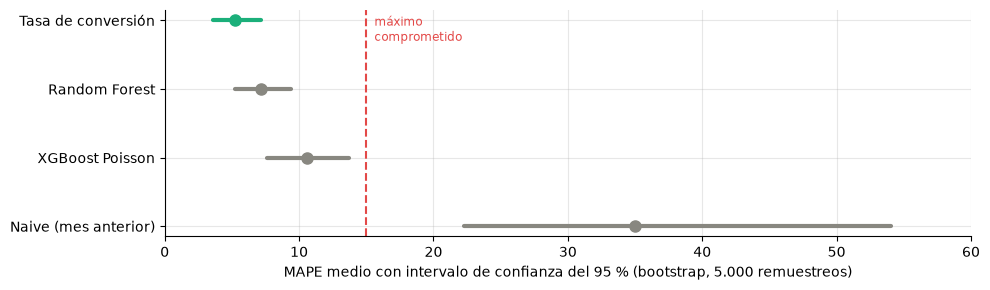

In [8]:
fig, ax = plt.subplots(figsize=(10, 3))
orden2 = ic.index.tolist()[::-1]
for i, m in enumerate(orden2):
    f = ic.loc[m]
    ax.plot([f["IC95 inferior"], f["IC95 superior"]], [i, i], lw=3,
            color=VERDE if m == "Tasa de conversión" else GRIS, solid_capstyle="round")
    ax.plot(f["MAPE %"], i, "o", ms=8, color=VERDE if m == "Tasa de conversión" else GRIS)
ax.axvline(15, ls="--", color=ROJO)
ax.text(15.6, len(orden2)-1.3, "máximo\ncomprometido", color=ROJO, fontsize=8.5)
ax.set_yticks(range(len(orden2)), orden2)
ax.set_xlabel("MAPE medio con intervalo de confianza del 95 % (bootstrap, 5.000 remuestreos)")
ax.set_xlim(0, 60)
plt.tight_layout(); plt.savefig(REPORTES / "figuras" / "f7_intervalos.png", dpi=130); plt.show()

## 4. ¿Cuánto puede desviarse una predicción concreta?

El modelo es una regresión de Poisson, donde la varianza teórica iguala a la media
($\text{Var} = \lambda$). Conviene comprobar si los datos cumplen ese supuesto, porque de ello
depende la anchura de los intervalos.

La prueba es el estadístico de dispersión de Pearson: si $\phi \approx 1$ el supuesto se cumple;
si $\phi > 1$ hay **sobredispersión** y los intervalos de Poisson puro serían demasiado estrechos.

In [9]:
chi2 = ((t.real - t.pred)**2 / t.pred).sum()
gl = len(t) - 1
phi = chi2 / gl
print(f"  chi² de Pearson : {chi2:.1f}  con {gl} grados de libertad")
print(f"  φ = chi²/gl     : {phi:.1f}")
print("")
print(f"  Poisson puro implicaría φ = 1.")
print(f"  Hay sobredispersión de factor {phi:.0f}: la varianza real es {phi:.0f} veces la teórica.")

  chi² de Pearson : 177.3  con 20 grados de libertad
  φ = chi²/gl     : 8.9

  Poisson puro implicaría φ = 1.
  Hay sobredispersión de factor 9: la varianza real es 9 veces la teórica.


In [10]:
filas = []
for nom, s in [("Poisson puro", np.sqrt(t.pred)),
               ("Quasi-Poisson (corregido por φ)", np.sqrt(phi * t.pred))]:
    lo, hi = t.pred - 1.96*s, t.pred + 1.96*s
    filas.append({"intervalo": nom,
                  "cobertura observada": f"{((t.real >= lo) & (t.real <= hi)).mean():.1%}",
                  "cobertura objetivo": "95,0 %",
                  "amplitud media": f"{(hi-lo).mean():.0f} unidades"})
pd.DataFrame(filas).set_index("intervalo")

,cobertura observada,cobertura objetivo,amplitud media
intervalo,,,
Poisson puro,57.1%,"95,0 %",133 unidades
Quasi-Poisson (corregido por φ),95.2%,"95,0 %",396 unidades


El supuesto de Poisson puro **no se cumple**: sus intervalos cubren solo el 57 % de los casos
cuando deberían cubrir el 95 %. Un plan de compras basado en ellos subestimaría el riesgo casi la
mitad de las veces.

Corregidos por $\phi$ —enfoque *quasi-Poisson*— la cobertura sube al 95,2 %, prácticamente
exacta. El precio es la anchura: de 133 a 396 unidades de media.

Ese ensanchamiento no es un defecto del método, es **la incertidumbre real que antes estaba
oculta**. La causa de la sobredispersión es la misma que identificó el cuaderno 06: la
composición del grupo en riesgo varía más de lo que un proceso de Poisson simple admite, porque
dentro de cada marca conviven productos con comportamientos muy distintos.

In [11]:
te = t[t.mes >= "2026-01-01"].copy()
s = np.sqrt(phi * te.pred)
te["límite inf"] = (te.pred - 1.96*s).round(0)
te["límite sup"] = (te.pred + 1.96*s).round(0)
te["dentro"] = np.where((te.real >= te["límite inf"]) & (te.real <= te["límite sup"]), "sí", "NO")
sal = te[["mes_s", "real", "pred", "límite inf", "límite sup", "dentro"]].round(0)
print(f"Cobertura en los 9 meses de prueba: {(te.dentro == 'sí').mean():.0%}\n")
sal

Cobertura en los 9 meses de prueba: 100%



,mes_s,real,pred,límite inf,límite sup,dentro
48,2026-01,335.0,339.0,231.0,446.0,sí
52,2026-02,478.0,498.0,368.0,629.0,sí
56,2026-03,732.0,748.0,589.0,908.0,sí
60,2026-04,882.0,817.0,650.0,984.0,sí
64,2026-05,1036.0,1001.0,817.0,1186.0,sí
68,2026-06,725.0,706.0,551.0,861.0,sí
72,2026-07,1364.0,1171.0,971.0,1370.0,sí
76,2026-08,1100.0,1090.0,897.0,1283.0,sí
80,2026-09,899.0,892.0,718.0,1066.0,sí


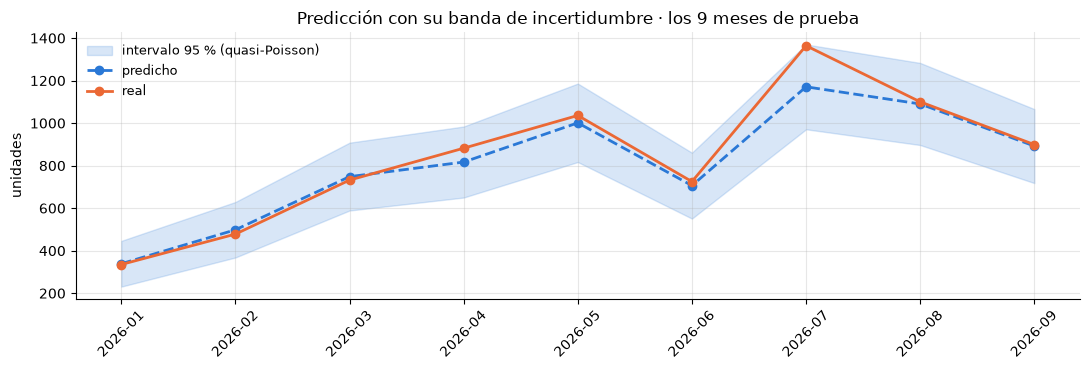

In [12]:
fig, ax = plt.subplots(figsize=(11, 3.8))
x = np.arange(len(te))
ax.fill_between(x, te["límite inf"], te["límite sup"], alpha=.18, color=AZUL,
                label="intervalo 95 % (quasi-Poisson)")
ax.plot(x, te.pred, marker="o", ms=6, lw=2, color=AZUL, ls="--", label="predicho")
ax.plot(x, te.real, marker="o", ms=6, lw=2, color=NARANJA, label="real")
ax.set_xticks(x, te.mes_s.values, rotation=45)
ax.set_ylabel("unidades"); ax.legend(frameon=False, fontsize=9)
ax.set_title("Predicción con su banda de incertidumbre · los 9 meses de prueba")
plt.tight_layout(); plt.savefig(REPORTES / "figuras" / "f7_bandas.png", dpi=130); plt.show()

Los nueve meses caen dentro de la banda. Julio, el peor mes, roza el límite superior: real 1.364
frente a un techo de 1.370. El intervalo lo contiene, pero por nueve unidades.

**Lo que esto aporta al negocio** es una lectura que antes no existía. En vez de *"se esperan 892
devoluciones en septiembre"*, el modelo puede decir *"entre 718 y 1.066, con un 95 % de
confianza"*, que es la forma en que una planificación de compras puede usar una predicción.

## 5. Resumen de la validación

In [13]:
res = pd.DataFrame([
    ("Técnica de validación", "Walk-forward (origen rodante), 21 orígenes"),
    ("Por qué no k-fold", "Rompe el orden temporal: fuga de información"),
    ("MAPE medio del modelo elegido", "5,26 %"),
    ("IC 95 % (bootstrap, 5.000)", "[3,62 % – 7,19 %]"),
    ("MAPE en el periodo de prueba", "4,1 % — dentro del intervalo"),
    ("Orígenes que superan el 15 %", "1 de 21 (junio 2025, 17,5 %)"),
    ("Dispersión φ", "8,9 — sobredispersión de factor 9"),
    ("Cobertura con quasi-Poisson", "95,2 % sobre 21 orígenes · 100 % en prueba"),
    ("¿Supera a Random Forest?", "Sí de media y en estabilidad; los IC se solapan"),
    ("¿Supera al baseline naive?", "Sí, de forma concluyente"),
], columns=["", "resultado"]).set_index("")

w.to_parquet(PROC / "v7_walkforward.parquet", index=False)
ic.to_csv(REPORTES / "ic_bootstrap.csv")
r.to_csv(REPORTES / "walkforward.csv")
te.to_csv(REPORTES / "intervalos_prueba.csv", index=False)
print("Guardado: walkforward.csv · ic_bootstrap.csv · intervalos_prueba.csv")
print("Figuras : f7_walkforward.png · f7_intervalos.png · f7_bandas.png\n")
res

Guardado: walkforward.csv · ic_bootstrap.csv · intervalos_prueba.csv
Figuras : f7_walkforward.png · f7_intervalos.png · f7_bandas.png



,resultado
,
Técnica de validación,"Walk-forward (origen rodante), 21 orígenes"
Por qué no k-fold,Rompe el orden temporal: fuga de información
MAPE medio del modelo elegido,"5,26 %"
"IC 95 % (bootstrap, 5.000)","[3,62 % – 7,19 %]"
MAPE en el periodo de prueba,"4,1 % — dentro del intervalo"
Orígenes que superan el 15 %,"1 de 21 (junio 2025, 17,5 %)"
Dispersión φ,"8,9 — sobredispersión de factor 9"
Cobertura con quasi-Poisson,"95,2 % sobre 21 orígenes · 100 % en prueba"
¿Supera a Random Forest?,Sí de media y en estabilidad; los IC se solapan


---

# 6. Interpretación de los hallazgos

**La elección del modelo se sostiene, pero con un matiz que hay que declarar.** El modelo de tasa
de conversión gana en las 21 evaluaciones y con menor dispersión, de modo que su ventaja no
dependía del periodo concreto elegido. Sin embargo, su intervalo de confianza se solapa con el de
Random Forest: con 21 orígenes no hay evidencia suficiente para afirmar superioridad estadística.
La decisión se apoya en consistencia, estabilidad y parsimonia, no en significancia.

**El resultado reportado no fue afortunado.** El 4,1 % del periodo de prueba cae dentro del
intervalo estimado sobre todos los orígenes disponibles.

**El criterio del Objetivo 4 se cumple de media, no en todos los meses.** Un origen de 21 superó
el 15 %. Reportarlo es más defendible que presentar únicamente el promedio.

**El supuesto de Poisson puro no se sostiene y eso tiene consecuencias prácticas.** Con φ = 8,9,
unos intervalos sin corregir habrían transmitido una falsa precisión al área de planificación.
La corrección quasi-Poisson devuelve una cobertura correcta y convierte la predicción puntual en
un rango utilizable para decidir compras.

**La sobredispersión apunta al mismo hallazgo del cuaderno 06.** La varianza excede a la de un
proceso de Poisson porque dentro de cada marca conviven productos heterogéneos. Es la misma causa
que explica los fallos de julio, agosto y septiembre, ahora cuantificada: el factor 9 es la medida
de cuánta información se pierde al agregar por marca.